# Prediction Uncertainty From Bootstrap Ensembles

This notebook inspects completed Phase 7 artifacts. It does not refit ensembles, regenerate outputs, or modify prior phases.

## Purpose And Boundaries

The objective is to measure sensitivity of predicted financial-stress probabilities to training-data resampling. Bootstrap predictive variance is a practical proxy for epistemic uncertainty. It is separate from probability calibration, evidence quality, OOD detection, and the future Safety Gate.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / 'experiments' / 'uncertainty'
sns.set_theme(style='whitegrid')

## What The Scores Mean

For each existing model family, 50 stratified bootstrap members are fit on resampled training applicants only. For member probabilities (p_b(x)), the mean probability is p_mean(x) and the primary uncertainty score is sample variance u_var(x)=Var_b[p_b(x)] with `ddof=1`. The notebook also reports standard deviation, 5th/95th bootstrap intervals, and predictive entropy of the ensemble mean.

Aleatoric uncertainty is irreducible outcome variation; epistemic uncertainty concerns limited-data/model sensitivity; predictive uncertainty concerns the final outcome distribution. The available observable synthetic data cannot separately identify individual aleatoric uncertainty. Predictive entropy is ambiguity around the mean probability, not epistemic uncertainty. LR-HGB disagreement is model-family disagreement, not calibrated confidence.

In [2]:
metadata = json.loads((OUTPUT_DIR / 'metadata.json').read_text())
thresholds = json.loads((OUTPUT_DIR / 'validation_thresholds.json').read_text())
scores = pd.read_csv(OUTPUT_DIR / 'uncertainty_scores.csv')
summary = pd.read_csv(OUTPUT_DIR / 'test_summary.csv')
curve = pd.read_csv(OUTPUT_DIR / 'selective_prediction_curve.csv')

metadata['stability']

{'hist_gradient_boosting': {'mean_absolute_difference': 0.001254123120045296,
  'median_absolute_difference': 0.00089028751355116,
  'median_relative_difference': 0.14768782956736987,
  'rank_correlation': 0.9336552238467662,
  'stable': True},
 'logistic_regression': {'mean_absolute_difference': 7.896643372772869e-05,
  'median_absolute_difference': 4.500716661480761e-05,
  'median_relative_difference': 0.17914849988289844,
  'rank_correlation': 0.9530611595827377,
  'stable': True}}

## Ensemble-Size Stability

The predeclared criterion compares first-25 and full-50 validation variance estimates: rank correlation must be at least 0.90 and median relative difference no more than 0.35 for each family. Test data is not used to choose ensemble size.

In [3]:
pd.DataFrame({
    'threshold': thresholds['thresholds'],
    'validation_flag_rate': thresholds['validation_flag_rates'],
}).T

,hist_gradient_boosting,logistic_regression
threshold,0.016287,0.000956
validation_flag_rate,0.050000,0.050000


## Validation Threshold Selection

Each model-family threshold is the 95th percentile of clean validation predictive variance. The intended validation uncertainty-flag rate is approximately 5%. Raw member probabilities are used; Phase 4 calibrators are not applied to bootstrap members.

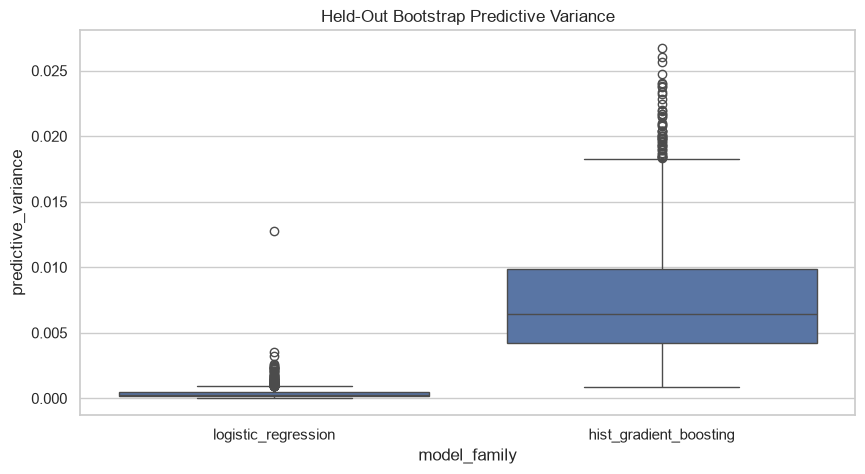

predictive_variance                                  \
                                     count    mean     std     min     25%   
model_family                                                                 
hist_gradient_boosting              1500.0  0.0075  0.0045  0.0009  0.0042   
logistic_regression                 1500.0  0.0004  0.0005  0.0000  0.0002   

                                               predictive_std          ...  \
                           50%     75%     max          count    mean  ...   
model_family                                                           ...   
hist_gradient_boosting  0.0065  0.0099  0.0267         1500.0  0.0831  ...   
logistic_regression     0.0003  0.0005  0.0127         1500.0  0.0184  ...   

                       predictive_entropy         model_family_disagreement  \
                                      75%     max                     count   
model_family                                                                  
hist_gradient_boosting             0.6705  0.6931                    1500.0   
logistic_regression                0.6724  0.6931                    1500.0   

                                                                             
                          mean     std  min     25%     50%     75%     max  
model_family                                                                 
hist_gradient_boosting  0.0524  0.0429  0.0  0.0189  0.0424  0.0736  0.3772  
logistic_regression     0.0524  0.0429  0.0  0.0189  0.0424  0.0736  0.3772  

[2 rows x 32 columns]

In [4]:
test_scores = scores[scores['evaluation_split'].eq('test')].copy()
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=test_scores, x='model_family', y='predictive_variance', ax=ax)
ax.set_title('Held-Out Bootstrap Predictive Variance')
plt.show()

test_scores.groupby('model_family')[['predictive_variance', 'predictive_std', 'predictive_entropy', 'model_family_disagreement']].describe().round(4)

## Test Evaluation And Selective Prediction

An error is an incorrect prediction at the existing fixed classification threshold of 0.50. Uncertainty is evaluated as an error-detection ranking score, not trained using error labels. Selective prediction retains the least-uncertain applicants as coverage decreases; risk is the retained classification error rate.

In [5]:
summary[summary['evaluation_split'].eq('test')].round(4)

,evaluation_split,model_family,ensemble_size,threshold,classification_threshold,uncertainty_flag_rate,retained_coverage,retained_brier_score,retained_log_loss,retained_classification_error_rate,error_detection_auroc,error_detection_auprc,error_rate,area_under_risk_coverage_curve
2,test,logistic_regression,50,0.0010,0.5,0.0533,0.9467,0.2077,0.6048,0.3106,0.5667,0.3493,0.3093,0.2750
3,test,hist_gradient_boosting,50,0.0163,0.5,0.0507,0.9493,0.2067,0.6031,0.3160,0.5882,0.3763,0.3213,0.2679


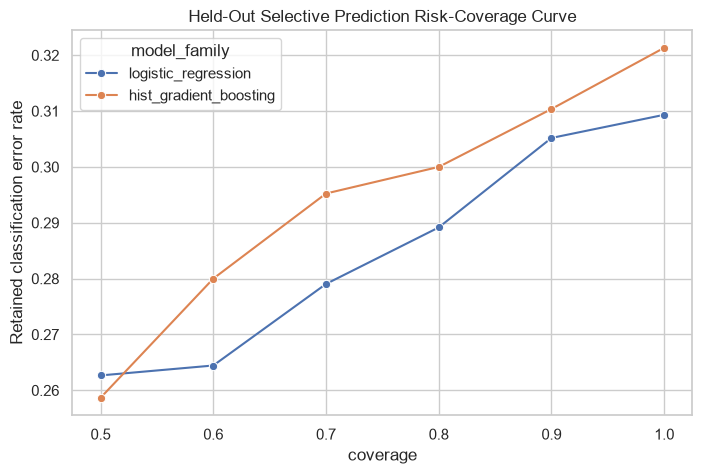

In [6]:
test_curve = curve[curve['evaluation_split'].eq('test')]
fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=test_curve, x='coverage', y='risk', hue='model_family', marker='o', ax=ax)
ax.set_title('Held-Out Selective Prediction Risk-Coverage Curve')
ax.set_ylabel('Retained classification error rate')
plt.show()

## Limitations

Bootstrap variance measures sensitivity to training-data resampling, not every form of epistemic uncertainty and not calibrated confidence. The synthetic outcome does not establish real-world uncertainty validity or reliable real-world credit decisions. These scores are not combined with OOD or evidence-quality scores in this phase.